# From Notebook to Production: Pipelines, Reproducibility, Safe Rollouts

**What you'll learn**

- How a typical "works on my machine" notebook workflow leaks label information and
  fragments preprocessing into artifacts that can never be kept in sync — and how to
  refactor it into a single sklearn `Pipeline` you can serialize, gate, and ship.
- The serialization contract seniors actually use: a `joblib` artifact plus a metadata
  sidecar (semantic version, environment pins, training-data hash, training metrics, and
  built-in smoke-test rows) so a loaded model can prove it is the model you think it is.
- Training–serving skew demonstrated live: two tiny, plausible serving-side bugs (a
  lowercased category, a missing-value default of `0`) that shift scores **without raising
  a single exception or warning** — and the input-schema validator that catches both.
- Reproducibility as an engineering discipline: deterministic training, environment pins,
  parquet data snapshots (and why CSV silently corrupts them), and **retrain-and-diff
  prediction regression tests** calibrated against a measured noise floor.
- Pre-deploy gates you can actually implement: frozen golden-dataset evaluation with a
  bootstrap CI on the challenger-vs-champion delta, plus behavioral tests (monotonicity,
  invariance, score sanity) that catch broken models a raw AUC gate misses.
- The rollout ladder — shadow, canary, champion/challenger, model A/B test — with a
  simulated shadow evaluation that catches a bad challenger *after* it passed every
  offline gate, because shadow tests the serving path, not just the artifact.

**Why it matters in interviews**

- "Walk me through taking a model from notebook to production" is the single most common
  senior ML system-design opener. Interviewers listen for artifacts, gates, rollout
  stages, and ownership — not for "I'd containerize it."
- Training–serving skew is the most common real-world production ML failure, and "how
  would you detect preprocessing drift between training and serving?" is a standard depth
  probe. The strong answer names concrete mechanisms, not vibes.
- "Your offline AUC is up 2 points — do you ship it?" tests whether you know the
  offline–online gap and the shadow → canary → A/B ladder.
- Reproducibility questions ("a retrain changed predictions — bug or noise?") separate
  people who have operated models from people who have only trained them.

Prerequisites: monitoring after rollout (PSI, drift taxonomy, retraining policy) lives in
[./01_drift_monitoring.ipynb](./01_drift_monitoring.ipynb); experiment design and
guardrails for model A/B tests in
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb);
power/MDE math used for canary sizing in
[../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb).

In [1]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.special import expit
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

ART = Path("artifacts")
ART.mkdir(exist_ok=True)


def file_sha256(path):
    """Content hash of a file on disk (first 16 hex chars for display)."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]


def dataframe_hash(df):
    """Deterministic content hash of a DataFrame (values, not index)."""
    return hashlib.sha256(
        pd.util.hash_pandas_object(df, index=False).values.tobytes()
    ).hexdigest()[:16]


def psi(expected, actual, bins=10):
    """Population Stability Index on quantile bins of `expected`.

    See ./01_drift_monitoring.ipynb for why the 0.1 / 0.25 folk thresholds are
    heuristics, not statistics. Here we only need PSI as a rough shift meter.
    """
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))

## 0. The setting: a subscription-churn model

We simulate a subscription business (streaming/SaaS-style). Each row is a customer; the
target is churn within the next billing cycle. The simulation is deliberately realistic
about the things that make production ML hard:

- **Missingness with structure.** `last_login_days` is missing *because* the customer
  never logged in — the highest-churn segment hides inside the NaNs. `monthly_spend` and
  `region` have random telemetry gaps.
- **Nonlinear risk.** Churn risk jumps after ~3 weeks of inactivity, is U-shaped in
  tenure (new-customer cliff *and* long-tenure "subscription fatigue"), spikes when new
  customers hit support problems, and has a "bill shock" step at high spend — structure
  a linear model cannot express, which is what will separate challenger from champion.
- **A high-cardinality categorical** (`promo_code`, ~1,200 levels) with **zero true
  effect** — the perfect trap for leaky target encoding: any measured lift from this
  feature is leakage by construction. `region` also has zero true effect, which we will
  exploit for an invariance test.

Because we own the data-generating process, we can generate *fresh* customers at will and
measure the **true** deployed performance of any workflow — the number production would
see. That is the yardstick for everything below.

In [2]:
PLAN_LEVELS = ["Basic", "Standard", "Premium"]
REGIONS = ["NA", "EU", "APAC", "LATAM"]
N_PROMO_CODES = 1200


def simulate_customers(n, rng, ultra_share=0.0):
    """Simulate customers with churn ground truth.

    ultra_share > 0 injects a new 'Ultra' plan (a product launch the training
    data never saw) — used for the live-traffic stream in section 5.
    """
    plan = rng.choice(PLAN_LEVELS, size=n, p=[0.45, 0.35, 0.20])
    if ultra_share > 0:
        plan = np.where(rng.random(n) < ultra_share, "Ultra", plan)
    region = rng.choice(REGIONS, size=n, p=[0.40, 0.30, 0.20, 0.10])
    tenure = np.clip(rng.gamma(2.0, 12.0, n), 1, 120).round()
    spend_base = pd.Series(plan).map(
        {"Basic": 25.0, "Standard": 45.0, "Premium": 80.0, "Ultra": 130.0}
    ).to_numpy()
    spend = spend_base * rng.lognormal(0.0, 0.25, n)
    tickets = rng.poisson(0.8, n)
    price_up = rng.choice([0.0, 5.0, 10.0, 20.0], size=n, p=[0.55, 0.20, 0.15, 0.10])
    promo = np.array([f"PC{i:04d}" for i in rng.integers(0, N_PROMO_CODES, n)])
    never_logged = rng.random(n) < 0.15
    login_days = np.round(rng.exponential(12.0, n)).clip(0, 90)

    plan_eff = pd.Series(plan).map(
        {"Basic": 0.45, "Standard": 0.0, "Premium": -0.35, "Ultra": 0.10}
    ).to_numpy()
    # Never-logged customers are the riskiest; among the rest, risk rises with
    # recency and jumps past 3 weeks of inactivity.
    login_term = np.where(
        never_logged,
        1.40,
        0.05 * np.minimum(login_days, 60) + 0.90 * (login_days > 21),
    )
    logit_p = (
        -1.75
        - 0.45 * np.log1p(tenure)
        + 0.50 * (tenure <= 3)                           # new-customer cliff
        + 0.80 * (tenure >= 48)                          # subscription fatigue (U-shape)
        + 0.05 * price_up
        + 0.35 * tickets
        + 0.50 * (tickets >= 2) * (tenure <= 12)         # new customers with problems bail
        + login_term
        + plan_eff
        + 0.50 * (price_up >= 10) * (plan == "Premium")  # interaction
        - 0.25 * np.log(spend / 40.0)
        + 0.55 * (spend > 110)                           # bill shock
        # region and promo_code have NO true effect — by design.
    )
    y = rng.binomial(1, expit(logit_p))

    df = pd.DataFrame({
        "tenure_months": tenure,
        "monthly_spend": spend,
        "plan": plan,
        "region": region,
        "promo_code": promo,
        "support_tickets_90d": tickets,
        "price_increase_pct": price_up,
        "last_login_days": login_days,
        "churned": y,
    })
    # Structured missingness: informative for logins, random gaps elsewhere.
    df.loc[never_logged, "last_login_days"] = np.nan
    df.loc[rng.random(n) < 0.08, "monthly_spend"] = np.nan
    df.loc[rng.random(n) < 0.05, "region"] = np.nan
    return df


NUM_COLS = ["tenure_months", "monthly_spend", "support_tickets_90d",
            "price_increase_pct", "last_login_days"]
OHE_COLS = ["plan", "region"]
TE_COLS = ["promo_code"]
FEATURES = NUM_COLS + OHE_COLS + TE_COLS          # challenger's input contract
CHAMP_FEATURES = NUM_COLS + OHE_COLS              # champion's input contract

train_raw = simulate_customers(15_000, rng)       # this year's training snapshot
fresh_raw = simulate_customers(10_000, rng)       # "next quarter" — deployment reality

print(f"churn rate: {train_raw['churned'].mean():.3f}")
print("missing rates:")
print(train_raw[FEATURES].isna().mean().round(3).to_string())
train_raw.head(4)

churn rate: 0.237
missing rates:
tenure_months          0.000
monthly_spend          0.079
support_tickets_90d    0.000
price_increase_pct     0.000
last_login_days        0.150
plan                   0.000
region                 0.046
promo_code             0.000


,tenure_months,monthly_spend,plan,region,promo_code,support_tickets_90d,price_increase_pct,last_login_days,churned
0,3.0,48.2489,Standard,NA,PC0440,2,5.0,13.0,0
1,8.0,18.8965,Basic,NA,PC0772,0,0.0,17.0,0
2,25.0,92.5109,Premium,NA,PC1067,3,10.0,2.0,0
3,8.0,53.8884,Standard,APAC,PC0153,0,0.0,15.0,1


## 1. From notebook chaos to a deployable artifact

### 1.1 The messy workflow (recognize it?)

The cell below is a faithful reconstruction of how models actually get built in
exploratory notebooks. It contains **three classic sins**:

1. **Impute using full-data statistics**, *then* split — mild leakage, real headache.
2. **Target-mean encode** `promo_code` **on the full data**, then split. Each row's own
   label is baked into its feature — including the "test" rows. This is the big one.
3. **`pd.get_dummies` on the full frame**, then split — the dummy-column layout now
   depends on which categories happened to be present, and nothing records it.

Beyond leakage, count the loose artifacts you'd have to ship to serve this model: two
median scalars, a 1,200-row `code_risk` mapping, the dummy-column layout, and the model.
Four things to version and keep in sync, forever, across two codebases. This is how
training–serving skew (section 2) is born.

In [3]:
# --- The messy notebook workflow (DON'T do this) -------------------------------
raw = train_raw.copy()

med_spend = raw["monthly_spend"].median()                 # full-data statistic
med_login = raw["last_login_days"].median()               # full-data statistic
raw["monthly_spend"] = raw["monthly_spend"].fillna(med_spend)
raw["last_login_days"] = raw["last_login_days"].fillna(med_login)
raw["region"] = raw["region"].fillna("(missing)")

code_risk = raw.groupby("promo_code")["churned"].mean()   # LEAK: uses every label
raw["promo_risk"] = raw["promo_code"].map(code_risk)

X_messy = pd.get_dummies(raw.drop(columns=["churned", "promo_code"]),
                         columns=["plan", "region"])      # layout captured nowhere
y_all = raw["churned"]

# ... and only NOW the split:
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_messy, y_all, test_size=0.3, stratify=y_all, random_state=42)

messy_model = HistGradientBoostingClassifier(random_state=42).fit(Xm_tr, ym_tr)
auc_messy_test = roc_auc_score(ym_te, messy_model.predict_proba(Xm_te)[:, 1])
print(f"messy workflow, 'held-out' test AUC (what the notebook claims): {auc_messy_test:.4f}")

messy workflow, 'held-out' test AUC (what the notebook claims): 0.8004


### 1.2 Deployment reality check

Now "deploy" the messy model on genuinely fresh customers. Note how much manual
bookkeeping even this simulation of serving needs (reusing the stored medians, mapping
unseen promo codes, `reindex`ing the dummy columns) — every line is a chance to diverge
from training. And the promo leak evaporates on fresh data, so the score drops.

In [4]:
f = fresh_raw.copy()
f["monthly_spend"] = f["monthly_spend"].fillna(med_spend)      # must remember training medians
f["last_login_days"] = f["last_login_days"].fillna(med_login)
f["region"] = f["region"].fillna("(missing)")
f["promo_risk"] = f["promo_code"].map(code_risk).fillna(code_risk.mean())  # unseen codes
Xf = pd.get_dummies(f.drop(columns=["churned", "promo_code"]),
                    columns=["plan", "region"])
Xf = Xf.reindex(columns=X_messy.columns, fill_value=0)         # column-sync tax

auc_messy_fresh = roc_auc_score(f["churned"], messy_model.predict_proba(Xf)[:, 1])
print(f"messy workflow, TRUE fresh-data AUC (what production gets): {auc_messy_fresh:.4f}")
print(f"optimism from leakage: {auc_messy_test - auc_messy_fresh:+.4f} AUC")

messy workflow, TRUE fresh-data AUC (what production gets): 0.6987
optimism from leakage: +0.1017 AUC


The notebook over-promised by a large margin, purely from encoding labels into a feature
*before* splitting. `promo_code` has **zero** true effect — every point of apparent lift
it contributed was leakage, and the model also *wasted capacity* on it, so true
performance is lower than a clean model's. In a real org, this is the model that
"degraded mysteriously right after launch."

### 1.3 The refactor: one fitted object, honest evaluation

The fix has two independent parts, and interviewers like hearing them separated:

1. **Statistical honesty:** split first; every fitted statistic (medians, category maps,
   target encodings) is learned inside the training fold only. sklearn's `TargetEncoder`
   even **cross-fits internally** during `fit_transform`, so the downstream model never
   sees a row's own label in its encoding (we also smooth it heavily — a 1,200-level
   code with ~10 observations per level carries almost no usable signal).
2. **Engineering:** the imputers, encoders, and model live in **one `Pipeline` object**
   with one `fit` and one `predict_proba`. There is exactly one artifact to version,
   test, and deploy — the preprocessing cannot drift away from the model because they
   are the same object.

Two deliberate configuration choices, both revisited in section 3: the encoder's
cross-fitting CV is **explicitly seeded**, and early stopping is **off** — together they
make training fully deterministic, which is what makes retrain-and-diff regression tests
sharp.

In [5]:
def make_challenger(clf_seed=42, early_stopping=False, add_indicator=False):
    """Full preprocessing + model in ONE object. This is the deployable artifact."""
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=add_indicator), NUM_COLS),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="constant", fill_value="(missing)")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), OHE_COLS),
        ("promo", TargetEncoder(                       # cross-fitted internally,
            smooth=30.0,                               # heavily smoothed (low-signal),
            cv=StratifiedKFold(5, shuffle=True, random_state=42),  # seeded -> deterministic
        ), TE_COLS),
    ])
    clf = HistGradientBoostingClassifier(
        random_state=clf_seed,
        early_stopping=early_stopping,   # off by default: deterministic retrains (see §3)
        min_samples_leaf=50,
        l2_regularization=1.0,
    )
    return Pipeline([("prep", prep), ("clf", clf)])


X_all, y_all = train_raw[FEATURES], train_raw["churned"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X_all, y_all, test_size=0.3, stratify=y_all, random_state=42)

challenger = make_challenger().fit(X_train, y_train)

auc_valid = roc_auc_score(y_valid, challenger.predict_proba(X_valid)[:, 1])
auc_fresh = roc_auc_score(fresh_raw["churned"],
                          challenger.predict_proba(fresh_raw[FEATURES])[:, 1])

summary = pd.DataFrame({
    "workflow": ["messy (leaky)", "messy (leaky)", "pipeline (honest)", "pipeline (honest)"],
    "evaluated on": ["'test' split", "fresh data", "validation split", "fresh data"],
    "AUC": [auc_messy_test, auc_messy_fresh, auc_valid, auc_fresh],
})
print(summary.to_string(index=False))

         workflow     evaluated on    AUC
    messy (leaky)     'test' split 0.8004
    messy (leaky)       fresh data 0.6987
pipeline (honest) validation split 0.7495
pipeline (honest)       fresh data 0.7453


The honest pipeline's validation AUC and its fresh-data AUC agree (up to sampling
noise) — the offline estimate is now *trustworthy*, which matters more than whether it
is higher or lower. Pre-deploy gates (section 4) are worthless if the offline number
lies. And the honest model beats the leaky one **on fresh data** — leakage didn't just
inflate the estimate, it produced a genuinely worse model.

### 1.4 Serialize with a metadata sidecar

`joblib.dump(pipe, path)` is the easy 10%. The senior 90% is the **sidecar**: a small
JSON committed next to the binary that makes the artifact auditable and self-checking:

- **identity**: model name, semantic version, timestamp;
- **environment pins**: python/sklearn/numpy/pandas versions — unpickling across sklearn
  versions is unsupported and can fail *silently subtly*, not just loudly;
- **data lineage**: content hash of the exact training snapshot (stored as parquet —
  see section 3 for why not CSV), row count;
- **training metrics**: what this artifact scored at build time, for later comparison;
- **smoke rows + expected scores**: five input rows and the scores the model produced at
  build time. Any loader can instantly verify "the model I loaded behaves identically to
  the model that was validated."

In [6]:
snapshot_path = ART / "train_snapshot.parquet"
train_raw.to_parquet(snapshot_path)

smoke_rows = X_valid.head(5)
meta = {
    "model_name": "churn_model",
    "version": "2.0.0-rc1",
    "created_utc": pd.Timestamp.utcnow().isoformat(),
    "python": sys.version.split()[0],
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "features": FEATURES,
    "target": "churned",
    "n_train_rows": int(len(X_train)),
    "deterministic_training": True,
    "train_snapshot_file_sha256": file_sha256(snapshot_path),
    "train_snapshot_df_hash": dataframe_hash(train_raw),
    "metrics": {"auc_valid": round(auc_valid, 6),
                "brier_valid": round(brier_score_loss(
                    y_valid, challenger.predict_proba(X_valid)[:, 1]), 6)},
    "seed": 42,
    "smoke_rows": smoke_rows.to_dict(orient="records"),
    "smoke_scores": challenger.predict_proba(smoke_rows)[:, 1].tolist(),
}

model_path, meta_path = ART / "churn_model_v2.joblib", ART / "churn_model_v2.meta.json"
joblib.dump(challenger, model_path)
with open(meta_path, "w") as fh:
    json.dump(meta, fh, indent=2, default=float)
print(f"artifact:  {model_path}  ({model_path.stat().st_size/1024:.0f} KiB)")
print(f"sidecar:   {meta_path}")
print(json.dumps({k: meta[k] for k in
                  ["version", "sklearn", "train_snapshot_file_sha256", "metrics"]}, indent=2))

artifact:  artifacts/churn_model_v2.joblib  (386 KiB)
sidecar:   artifacts/churn_model_v2.meta.json
{
  "version": "2.0.0-rc1",
  "sklearn": "1.9.0",
  "train_snapshot_file_sha256": "645aca96128d77ce",
  "metrics": {
    "auc_valid": 0.749495,
    "brier_valid": 0.151356
  }
}


In [7]:
def load_model_checked(model_path, meta_path):
    """Load a model artifact and refuse to serve it unless it proves itself."""
    with open(meta_path) as fh:
        meta = json.load(fh)
    if meta["sklearn"] != sklearn.__version__:
        raise RuntimeError(
            f"sklearn mismatch: artifact built on {meta['sklearn']}, "
            f"runtime has {sklearn.__version__} — rebuild, don't hope.")
    model = joblib.load(model_path)
    smoke_X = pd.DataFrame(meta["smoke_rows"])[meta["features"]]
    got = model.predict_proba(smoke_X)[:, 1]
    np.testing.assert_allclose(got, meta["smoke_scores"], atol=1e-8,
                               err_msg="loaded model disagrees with build-time scores")
    return model, meta


served_model, served_meta = load_model_checked(model_path, meta_path)
print(f"loaded {served_meta['model_name']} v{served_meta['version']}: smoke test PASSED")

# A version-mismatch scenario: the guard refuses instead of serving garbage.
tampered = dict(meta, sklearn="1.4.2")
with open(ART / "_tampered.meta.json", "w") as fh:
    json.dump(tampered, fh, default=float)
try:
    load_model_checked(model_path, ART / "_tampered.meta.json")
except RuntimeError as e:
    print(f"guard raised as intended: {e}")

loaded churn_model v2.0.0-rc1: smoke test PASSED
guard raised as intended: sklearn mismatch: artifact built on 1.4.2, runtime has 1.9.0 — rebuild, don't hope.


## 2. Training–serving skew: the silent killer

Training–serving skew = *the features the model sees in production are computed
differently than the features it was trained on*. It is arguably the most common
production-ML failure mode, and its signature is **silence**: nothing errors, nothing
pages, scores just quietly mean something different. Standard causes:

| Cause | Example |
|---|---|
| Two codebases | pandas in training, Java/SQL re-implementation at serving |
| NA semantics | training saw `NaN`; serving upstream "helpfully" defaults to `0` / `""` / `-999` |
| Category normalization | `"Premium"` vs `"premium"` vs `"PREMIUM"` after an ingest refactor |
| dtype coercion | JSON turns ints into floats/strings; `"5"` ≠ `5` after encoding |
| Units / scaling | dollars vs cents, seconds vs ms, percent vs fraction |
| Feature staleness | serving reads a feature store lagged hours behind training joins |

The single pipeline from section 1 eliminates the *two-codebases* cause. It cannot
protect you from what happens **upstream of the pipeline**.

Meet the incumbent: the **champion** currently in production is a logistic regression
trained a year ago on last year's 2,500-customer snapshot (the product was smaller
then) — simple, robust, and due for replacement (that vintage matters in section 4).
Now watch what happens when the ingest team ships "v2" of the events job with two
innocuous-looking changes.

In [8]:
old_raw = simulate_customers(2_500, rng)          # last year's snapshot
champion = Pipeline([                             # the incumbent production model
    ("prep", ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), NUM_COLS),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="(missing)")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore",
                                                sparse_output=False))]), OHE_COLS),
    ])),
    ("clf", LogisticRegression(max_iter=2000, random_state=42)),
]).fit(old_raw[CHAMP_FEATURES], old_raw["churned"])

serve_raw = simulate_customers(6_000, rng)        # this week's scoring batch


def ingest_v2(df):
    """The new upstream ingest job. Both changes looked reasonable in code review."""
    out = df.copy()
    out["plan"] = out["plan"].str.lower()                       # "normalize strings"
    out["monthly_spend"] = out["monthly_spend"].fillna(0.0)     # "avoid nulls downstream"
    return out


X_clean = serve_raw[CHAMP_FEATURES]
X_skewed = ingest_v2(serve_raw)[CHAMP_FEATURES]

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    s_clean = champion.predict_proba(X_clean)[:, 1]
    s_skewed = champion.predict_proba(X_skewed)[:, 1]

print(f"exceptions raised: 0 | warnings emitted: {len(caught)} — total silence.")

skew_report = pd.DataFrame({
    "metric": ["mean score", "AUC on this batch", "PSI vs clean scores",
               "share of customers with |Δscore| > 0.05"],
    "clean path": [s_clean.mean(), roc_auc_score(serve_raw["churned"], s_clean),
                   0.0, 0.0],
    "skewed path": [s_skewed.mean(), roc_auc_score(serve_raw["churned"], s_skewed),
                    psi(s_clean, s_skewed),
                    float(np.mean(np.abs(s_skewed - s_clean) > 0.05))],
})
print("\n" + skew_report.to_string(index=False))

exceptions raised: 0 | warnings emitted: 0 — total silence.

                                 metric  clean path  skewed path
                             mean score      0.2318       0.2168
                      AUC on this batch      0.7375       0.7225
                    PSI vs clean scores      0.0000       0.0138
share of customers with |Δscore| > 0.05      0.0000       0.3398


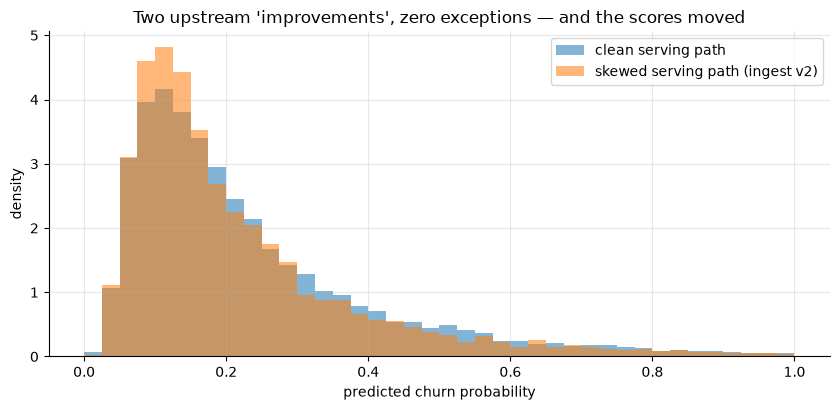

In [9]:
fig, ax = plt.subplots()
bins = np.linspace(0, 1, 41)
ax.hist(s_clean, bins=bins, alpha=0.55, label="clean serving path", density=True)
ax.hist(s_skewed, bins=bins, alpha=0.55, label="skewed serving path (ingest v2)", density=True)
ax.set_xlabel("predicted churn probability")
ax.set_ylabel("density")
ax.set_title("Two upstream 'improvements', zero exceptions — and the scores moved")
ax.legend()
plt.show()

Dissect what happened:

- `"basic"` / `"standard"` / `"premium"` are **unknown categories** to the fitted
  `OneHotEncoder`. With `handle_unknown="ignore"` they encode as all-zeros: every
  customer silently lost their plan signal. That flag is a double-edged sword — it keeps
  serving alive through benign novelty *and* it swallows catastrophic skew, without so
  much as a log line.
- Missing `monthly_spend` now arrives as `0.0`, a value **below the training minimum**.
  The median imputer never fires (nothing is missing anymore) and the model happily
  extrapolates. Ranking quality (AUC) degrades and the score *level* shifts — bad news
  if a retention team intervenes on everyone above a fixed threshold.

### 2.1 The defense: validate inputs at the serving boundary

The model's input contract should be enforced in code, per batch, *before* scoring. The
validator below is ~40 lines and catches both bugs. Key design choice: checks are
**rate-based** ("what fraction of rows violate"), not row-based — a single tail outlier
should not page anyone, but 8% of rows below the training minimum absolutely should.
(In production you'd reach for `pandera`/`pydantic`/Great Expectations; the logic is
exactly this.)

In [10]:
def build_schema(df, num_cols, cat_cols):
    """Freeze the input contract from the production model's training data."""
    schema = {}
    for c in num_cols:
        s = df[c]
        schema[c] = {"kind": "num", "min": float(s.min()), "max": float(s.max()),
                     "missing_rate": float(s.isna().mean())}
    for c in cat_cols:
        s = df[c]
        schema[c] = {"kind": "cat", "levels": set(s.dropna().unique()),
                     "missing_rate": float(s.isna().mean())}
    return schema


def validate_serving_batch(df, schema, max_oob=0.005, max_unknown=0.005, miss_tol=0.05):
    """Return a list of human-readable violations (empty list = batch accepted)."""
    issues = [f"{c}: REQUIRED COLUMN MISSING" for c in schema if c not in df.columns]
    for c, spec in schema.items():
        if c not in df.columns:
            continue
        s = df[c]
        miss = float(s.isna().mean())
        if abs(miss - spec["missing_rate"]) > miss_tol:
            issues.append(f"{c}: missing-rate {miss:.1%} vs {spec['missing_rate']:.1%} "
                          f"in training (Δ > {miss_tol:.0%})")
        if spec["kind"] == "num":
            if not pd.api.types.is_numeric_dtype(s):
                issues.append(f"{c}: expected numeric dtype, got {s.dtype}")
                continue
            oob = float(((s < spec["min"]) | (s > spec["max"])).mean())
            if oob > max_oob:
                issues.append(f"{c}: {oob:.1%} of values outside training range "
                              f"[{spec['min']:.2f}, {spec['max']:.2f}]")
        else:
            unknown_mask = s.notna() & ~s.isin(spec["levels"])
            if unknown_mask.mean() > max_unknown:
                examples = sorted(s[unknown_mask].unique())[:3]
                issues.append(f"{c}: {unknown_mask.mean():.1%} unknown levels, "
                              f"e.g. {examples}")
    return issues


schema = build_schema(old_raw[CHAMP_FEATURES], NUM_COLS, OHE_COLS)

for name, batch in [("clean batch", X_clean), ("ingest-v2 batch", X_skewed)]:
    issues = validate_serving_batch(batch, schema)
    verdict = "ACCEPTED" if not issues else f"REJECTED ({len(issues)} violations)"
    print(f"{name}: {verdict}")
    for i in issues:
        print(f"   - {i}")

clean batch: ACCEPTED
ingest-v2 batch: REJECTED (3 violations)
   - monthly_spend: missing-rate 0.0% vs 7.7% in training (Δ > 5%)
   - monthly_spend: 8.5% of values outside training range [11.98, 166.26]
   - plan: 100.0% unknown levels, e.g. ['basic', 'premium', 'standard']


The validator rejects the skewed batch for exactly the right reasons: unknown `plan`
levels, `monthly_spend` values below the training range, and a missing-rate that
collapsed from ~8% to 0% (the subtlest tell — *disappearing* missingness is as
suspicious as new missingness). The clean batch sails through, including its natural
tail values — because the checks are rate-based.

## 3. Reproducibility: seeds, pins, snapshots, prediction diffs

"Can you rebuild the model you're serving, bit for bit?" is a production question, not
an academic one: you need it for debugging ("is the new behavior from my change or from
noise?"), for compliance, and for incident recovery. Three layers:

1. **Determinism by construction** — every stochastic component either pinned or
   removed. Our pipeline seeds the target encoder's CV shuffle and turns early stopping
   off, so two fits on the same data are *bit-identical*.
2. **Environment** — versions pinned in the sidecar plus a lockfile/container image;
   "same code, newer sklearn" is a different model.
3. **Data** — a content-hashed snapshot of the training frame. "We trained on the
   warehouse as of roughly Tuesday" is not reproducible.

With those three, **retrain-and-diff** becomes a regression test: retrain from the
snapshot, score a frozen set, compare predictions to the artifact's. Identical, or
explain why.

In [11]:
def load_snapshot(path):
    df = pd.read_parquet(path)
    for c in df.columns[df.dtypes == object]:
        # Parquet returns missing strings as None; sklearn's imputers only treat
        # np.nan as missing. Normalize — sneakily, pandas' row-hash treats None
        # and NaN as equal, so a hash check alone would NOT catch this.
        df[c] = df[c].fillna(np.nan)
    return df


snap = load_snapshot(snapshot_path)
assert file_sha256(snapshot_path) == meta["train_snapshot_file_sha256"], "snapshot changed!"
Xs, ys = snap[FEATURES], snap["churned"]
Xs_tr, _, ys_tr, _ = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=42)

retrained = make_challenger().fit(Xs_tr, ys_tr)
ref_scores = challenger.predict_proba(X_valid)[:, 1]
d_same = np.abs(retrained.predict_proba(X_valid)[:, 1] - ref_scores)
print(f"retrain from snapshot, same config: max |Δ score| = {d_same.max():.2e}")

retrain from snapshot, same config: max |Δ score| = 0.00e+00


Bit-identical. Now the pitfall that motivated the parquet choice: **CSV is not a
snapshot format.** Watch what a CSV round-trip does to this exact dataset.

In [12]:
csv_path = ART / "_snapshot_the_wrong_way.csv"
train_raw.to_csv(csv_path, index=False)
naive_reload = pd.read_csv(csv_path)

print(f"region missing rate: original {train_raw['region'].isna().mean():.1%} "
      f"-> after CSV round-trip {naive_reload['region'].isna().mean():.1%}")
print(f"dataframe hash match: {dataframe_hash(naive_reload) == dataframe_hash(train_raw)}")
print(f"monthly_spend exactly equal: "
      f"{naive_reload['monthly_spend'].equals(train_raw['monthly_spend'])}")

region missing rate: original 4.6% -> after CSV round-trip 42.2%
dataframe hash match: False
monthly_spend exactly equal: False


Two silent corruptions in one innocent `to_csv`/`read_csv` round-trip:

- Our largest region is literally named `"NA"` — and `read_csv` parses `"NA"` as
  *missing* by default. Forty percent of customers just lost their region. (Yes, this
  happens constantly in real life: country code "NA" is Namibia.)
- Default float parsing is fast, not round-trip exact; values drift in the last ulps,
  enough to change tree split decisions on retrain.

You can patch both (`keep_default_na=False`, `float_precision="round_trip"`), but the
senior move is a typed, binary format (parquet) — and the content-hash check in the
sidecar, which is what actually *caught* the corruption here.

### 3.1 The noise floor: how much would retraining move predictions anyway?

Our pipeline is deterministic, so any retrain diff demands an explanation. Most
pipelines are not: early stopping carves a random validation split, forests bootstrap,
neural nets shuffle batches. Before you can set a diff-test threshold you must **measure
your pipeline's noise floor**. Here is what just *one* config flag does — the same
model with `early_stopping=True` and two different seeds:

In [13]:
es_a = make_challenger(clf_seed=0, early_stopping=True).fit(X_train, y_train)
es_b = make_challenger(clf_seed=1, early_stopping=True).fit(X_train, y_train)
d_es = np.abs(es_a.predict_proba(X_valid)[:, 1] - es_b.predict_proba(X_valid)[:, 1])
print(f"early_stopping=True, seed 0 vs seed 1:  p99 |Δ score| = {np.quantile(d_es, 0.99):.4f}"
      f"  |  share with |Δ| > 0.02 = {(d_es > 0.02).mean():.1%}")

early_stopping=True, seed 0 vs seed 1:  p99 |Δ score| = 0.1374  |  share with |Δ| > 0.02 = 49.6%


One flag, and 1% of customers move by more than a dozen probability points between two
"identical" trainings. Boosting amplifies small perturbations chaotically — a fact most
people discover only when a retrain "mysteriously" reshuffles their top-decile list.
If your pipeline keeps stochastic components, *this* number — not zero — is the baseline
any regression test must beat.

### 3.2 An "innocent improvement" caught by the diff test

A teammate refactors the imputer to `add_indicator=True` ("the model should know what
was missing — strictly more information, can't hurt"). Correct, and it probably *helps*
AUC — missingness is informative here. But watch the prediction diff:

In [14]:
improved = make_challenger(add_indicator=True).fit(X_train, y_train)
imp_scores = improved.predict_proba(X_valid)[:, 1]


def diff_stats(new_scores, name):
    d = np.abs(new_scores - ref_scores)
    return {"variant": name, "max|Δ|": d.max(),
            "p99|Δ|": np.quantile(d, 0.99), "share |Δ|>0.02": (d > 0.02).mean()}


diff_table = pd.DataFrame([
    diff_stats(retrained.predict_proba(X_valid)[:, 1], "retrain, same config"),
    diff_stats(imp_scores, "code change: add_indicator=True"),
])
print(diff_table.to_string(index=False))

d_code = np.abs(imp_scores - ref_scores)
had_missing = X_valid[NUM_COLS].isna().any(axis=1).to_numpy()
slice_view = pd.DataFrame({
    "slice": ["rows with imputed values", "fully observed rows"],
    "n": [int(had_missing.sum()), int((~had_missing).sum())],
    "p99|Δ|": [np.quantile(d_code[had_missing], 0.99),
               np.quantile(d_code[~had_missing], 0.99)],
    "mean|Δ|": [d_code[had_missing].mean(), d_code[~had_missing].mean()],
})
print("\n" + slice_view.to_string(index=False))

                        variant  max|Δ|  p99|Δ|  share |Δ|>0.02
           retrain, same config  0.0000  0.0000          0.0000
code change: add_indicator=True  0.3989  0.1643          0.5211

                   slice    n  p99|Δ|  mean|Δ|
rows with imputed values  994  0.1732   0.0414
     fully observed rows 3506  0.1587   0.0307


Read this like a senior:

- The diff is enormous relative to a deterministic baseline of zero — the change is
  *visible*, immediately, without waiting for any metric to move.
- The diffs are larger on imputed rows (where the model can now see missingness) but far
  from confined to them: boosting's retraining cascade spreads any change everywhere.
  Aggregate diffs tell you **that** behavior changed; provenance — the config diff and
  the data hash — tells you **why**. Don't expect GBM diffs to localize cleanly.
- "Visible" is not "bad": this change is likely an improvement. But a shifted score
  distribution silently breaks every downstream threshold tuned on the old scores.
  Detect, review, re-gate, retune — that is the point of the test.

In [15]:
def prediction_regression_test(candidate, X, ref_scores, tol):
    """PASS if candidate predictions match the reference within tol at p99.

    For a deterministic pipeline tol can be ~0 (we use 1e-6). If your pipeline
    keeps stochastic components, set tol ~= 2x the measured seed-noise floor.
    """
    p99 = np.quantile(np.abs(candidate.predict_proba(X)[:, 1] - ref_scores), 0.99)
    return ("PASS" if p99 <= tol else "INVESTIGATE"), p99


for name, m in [("retrain, same config", retrained), ("add_indicator variant", improved)]:
    verdict, p99 = prediction_regression_test(m, X_valid, ref_scores, tol=1e-6)
    print(f"{name:24s} p99|Δ|={p99:.2e}  ->  {verdict}")

retrain, same config     p99|Δ|=0.00e+00  ->  PASS
add_indicator variant    p99|Δ|=1.64e-01  ->  INVESTIGATE


## 4. Pre-deploy gates: golden data, challenger vs champion, behavioral tests

Nothing reaches a rollout (section 5) without passing automated gates in CI. Three
families, in increasing order of how often they're forgotten:

1. **Frozen golden-dataset evaluation.** A labeled, versioned, content-hashed holdout
   that *never* touches training. Every candidate — human-built or auto-retrained — is
   scored on the same rows, so numbers are comparable across months. (Golden sets go
   stale as traffic drifts; that failure mode is exactly what section 5 exposes.)
2. **Challenger vs champion.** The candidate must beat the *current production model*,
   with uncertainty quantified on the **paired** delta — not two overlapping marginal
   CIs. Our challenger has two honest advantages: a nonlinear model (the U-shaped
   tenure effect and the interactions are invisible to a linear champion), and a year
   fresher, 4x larger training set.
3. **Behavioral tests** — unit tests for model *behavior*, not accuracy: known-direction
   effects must be monotone, irrelevant attributes must not move scores, outputs must be
   sane on edge-case inputs. These catch sign-flip bugs, join misalignments, and feature
   corruption that AUC alone can miss until it's too late.

In [16]:
golden = simulate_customers(4_000, rng)            # frozen labeled sample, last quarter
golden_path = ART / "golden_eval.parquet"
golden.to_parquet(golden_path)
print(f"golden set frozen: {golden_path}  sha256={file_sha256(golden_path)}  "
      f"n={len(golden)}  churn={golden['churned'].mean():.3f}")

gy = golden["churned"].to_numpy()
champ_g = champion.predict_proba(golden[CHAMP_FEATURES])[:, 1]
chal_g = challenger.predict_proba(golden[FEATURES])[:, 1]

auc_champ_g = roc_auc_score(gy, champ_g)
auc_chal_g = roc_auc_score(gy, chal_g)

# Paired bootstrap CI on the AUC delta — resample ROWS, score both models on the
# same resample. Never compare two independent CIs and eyeball the overlap.
boot_idx = rng.integers(0, len(gy), size=(400, len(gy)))
deltas = np.array([roc_auc_score(gy[i], chal_g[i]) - roc_auc_score(gy[i], champ_g[i])
                   for i in boot_idx])
lo, hi = np.quantile(deltas, [0.025, 0.975])
print(f"\nchampion   golden AUC: {auc_champ_g:.4f}")
print(f"challenger golden AUC: {auc_chal_g:.4f}")
print(f"paired ΔAUC = {auc_chal_g - auc_champ_g:+.4f}, 95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]")

golden set frozen: artifacts/golden_eval.parquet  sha256=dc7fb14c75448ceb  n=4000  churn=0.245



champion   golden AUC: 0.7285
challenger golden AUC: 0.7490
paired ΔAUC = +0.0205, 95% bootstrap CI [+0.0070, +0.0343]


### 4.1 Behavioral tests

We probe the fitted model like a physical system. `mean_response_curve` is a partial-
dependence-style probe: override one feature on a sample of real customers, average the
scores. Averaging over a probe set (rather than one synthetic row) makes the check
stable for tree models, whose individual predictions are step functions.

- **Monotonicity**: bigger price increases and more support tickets must not *decrease*
  predicted churn — and must produce a material rise (a flat response to price is itself
  a red flag given domain knowledge, so we require `min_rise` too). If you need
  monotonicity guaranteed rather than tested,
  `HistGradientBoostingClassifier(monotonic_cst=...)` enforces it at fit time.
- **Invariance**: `region` carries no legitimate signal in this product; swapping it
  should barely move the average score. The same template implements fairness smoke
  tests on protected attributes.
- **Sanity**: scores are finite, strictly inside (0, 1), and the model doesn't crash on
  rows where every optional field is missing.

In [17]:
def mean_response_curve(model, X_probe, feature, grid):
    means = []
    for v in grid:
        Xp = X_probe.copy()
        Xp[feature] = v
        means.append(model.predict_proba(Xp)[:, 1].mean())
    return np.asarray(means)


def gate_monotone(model, X_probe, feature, grid, tol=0.002, min_rise=0.01):
    curve = mean_response_curve(model, X_probe, feature, grid)
    ok = bool(np.all(np.diff(curve) >= -tol) and (curve[-1] - curve[0] >= min_rise))
    return ok, curve


def gate_invariance(model, X_probe, feature, levels, max_spread=0.03):
    means = [mean_response_curve(model, X_probe, feature, [lv])[0] for lv in levels]
    spread = float(np.max(means) - np.min(means))
    return spread <= max_spread, spread


def gate_sanity(model, X_probe):
    s = model.predict_proba(X_probe)[:, 1]
    edge = X_probe.head(20).copy()
    edge[["monthly_spend", "last_login_days"]] = np.nan
    edge["region"] = np.nan
    s_edge = model.predict_proba(edge)[:, 1]
    ok = bool(np.isfinite(s).all() and (s > 0).all() and (s < 1).all()
              and np.isfinite(s_edge).all())
    return ok, float(s.min()), float(s.max())


PRICE_GRID = [0, 5, 10, 15, 20, 25, 30]
TICKET_GRID = [0, 1, 2, 3, 4, 5]


def run_predeploy_gates(candidate, name, min_auc_gain=0.005):
    probe = golden[FEATURES].sample(400, random_state=42)
    s = candidate.predict_proba(golden[FEATURES])[:, 1]
    auc = roc_auc_score(gy, s)
    brier = brier_score_loss(gy, s)
    brier_champ = brier_score_loss(gy, champ_g)
    mono_price, _ = gate_monotone(candidate, probe, "price_increase_pct", PRICE_GRID)
    mono_tix, _ = gate_monotone(candidate, probe, "support_tickets_90d", TICKET_GRID)
    inv_ok, spread = gate_invariance(candidate, probe, "region", REGIONS)
    sane, smin, smax = gate_sanity(candidate, golden[FEATURES])
    gates = pd.DataFrame([
        ("golden AUC beats champion", f">= champ {auc_champ_g:.4f} + {min_auc_gain}",
         f"{auc:.4f}", auc >= auc_champ_g + min_auc_gain),
        ("golden Brier not worse", f"<= champ {brier_champ:.4f} + 0.001",
         f"{brier:.4f}", brier <= brier_champ + 0.001),
        ("monotone: price increase -> churn up", "non-decreasing, rise >= 0.01",
         "curve", mono_price),
        ("monotone: tickets -> churn up", "non-decreasing, rise >= 0.01",
         "curve", mono_tix),
        ("invariance: region", "mean-score spread <= 0.03", f"{spread:.4f}", inv_ok),
        ("score sanity", "finite, in (0,1), NaN-robust",
         f"[{smin:.3f}, {smax:.3f}]", sane),
    ], columns=["gate", "threshold", "value", "passed"])
    verdict = "ALL GATES PASSED" if gates["passed"].all() else "BLOCKED"
    print(f"=== {name}: {verdict} ===")
    print(gates.to_string(index=False))
    return gates


gates_ok = run_predeploy_gates(challenger, "challenger v2.0.0-rc1")

=== challenger v2.0.0-rc1: ALL GATES PASSED ===
                                gate                    threshold          value  passed
           golden AUC beats champion      >= champ 0.7285 + 0.005         0.7490    True
              golden Brier not worse      <= champ 0.1584 + 0.001         0.1562    True
monotone: price increase -> churn up non-decreasing, rise >= 0.01          curve    True
       monotone: tickets -> churn up non-decreasing, rise >= 0.01          curve    True
                  invariance: region    mean-score spread <= 0.03         0.0098    True
                        score sanity finite, in (0,1), NaN-robust [0.015, 0.943]    True


### 4.2 What a broken model looks like at the gates

A realistic disaster: an automated retrain where an off-by-one join **misaligned labels
by one row**. The pipeline fits without complaint and produces perfectly
plausible-looking scores. The gates shred it — note that *multiple independent* gates
fire, which is the design goal: no single check should be a lone point of failure.

In [18]:
y_misaligned = pd.Series(np.roll(y_train.to_numpy(), 1), index=y_train.index)
bad_challenger = make_challenger().fit(X_train, y_misaligned)
gates_bad = run_predeploy_gates(bad_challenger, "bad challenger (labels misaligned by 1 row)")

=== bad challenger (labels misaligned by 1 row): BLOCKED ===
                                gate                    threshold          value  passed
           golden AUC beats champion      >= champ 0.7285 + 0.005         0.4700   False
              golden Brier not worse      <= champ 0.1584 + 0.001         0.1925   False
monotone: price increase -> churn up non-decreasing, rise >= 0.01          curve   False
       monotone: tickets -> churn up non-decreasing, rise >= 0.01          curve   False
                  invariance: region    mean-score spread <= 0.03         0.0263    True
                        score sanity finite, in (0,1), NaN-robust [0.064, 0.614]    True


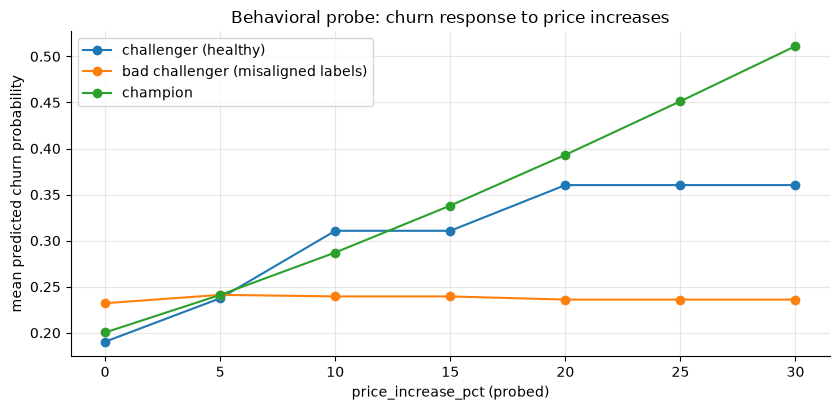

In [19]:
probe = golden[FEATURES].sample(400, random_state=42)
fig, ax = plt.subplots()
for model, label, cols in [(challenger, "challenger (healthy)", FEATURES),
                           (bad_challenger, "bad challenger (misaligned labels)", FEATURES),
                           (champion, "champion", CHAMP_FEATURES)]:
    ax.plot(PRICE_GRID,
            mean_response_curve(model, probe[cols], "price_increase_pct", PRICE_GRID),
            marker="o", label=label)
ax.set_xlabel("price_increase_pct (probed)")
ax.set_ylabel("mean predicted churn probability")
ax.set_title("Behavioral probe: churn response to price increases")
ax.legend()
plt.show()

## 5. Rollout patterns: shadow -> canary -> A/B

Passing offline gates earns a model *exposure to traffic*, not customers. The ladder:

| Pattern | What it tests | Customer risk | What it CANNOT tell you |
|---|---|---|---|
| **Shadow mode** | full serving path: feature fetch, latency, score distribution; live accuracy once labels mature | zero — challenger scores are logged, never acted on | business impact of *acting* on the scores; feedback effects |
| **Canary** | end-to-end behavior on a small slice (say 5%) with real actions | small, bounded | small regressions quickly (power!); heterogeneous effects |
| **Champion/challenger** | ongoing: challenger(s) continuously scored & compared in shadow | zero until promotion | same limits as shadow |
| **Model A/B test** | causal business impact (retention, revenue) with guardrails | controlled, measured | anything about segments you didn't power for |

Two senior points interviewers listen for:

- **Offline metrics are proxies.** The A/B decision metric is the business outcome
  (retention, margin), with guardrails — see
  [../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb).
  Randomize by *customer*, not by request, or you test nothing coherent.
- **Shadow tests the path, not the artifact.** Offline gates score a pickled model on a
  clean parquet. Shadow runs the *real* feature-fetch code on *live* traffic. Different
  things fail in each.

### 5.1 Shadow mode catches what every offline gate missed

Our challenger passed every gate in section 4. It now ships to shadow behind a **new
low-latency feature service** — whose author made cache misses return `0` instead of
null. Sound familiar? It is the same bug class as section 2, but this time *inside the
challenger's own serving path*, so no offline evaluation could ever have seen it. Live
traffic also now includes a newly launched "Ultra" plan (~5% of customers) that neither
model has seen — realistic golden-set staleness.

In [20]:
def challenger_serving_path(batch):
    """The challenger's NEW feature-fetch service: cache misses return 0, not null."""
    X = batch[FEATURES].copy()
    X["last_login_days"] = X["last_login_days"].fillna(0.0)     # THE BUG
    return X


weeks, batches = 8, []
shadow_log = []
chal_offline_ref = chal_g                       # challenger's golden-set score distribution
champ_offline_ref = champ_g

for w in range(1, weeks + 1):
    batch = simulate_customers(1_500, rng, ultra_share=0.05)    # live traffic, drifted
    batches.append(batch)
    s_champ = champion.predict_proba(batch[CHAMP_FEATURES])[:, 1]
    s_chal = challenger.predict_proba(challenger_serving_path(batch))[:, 1]
    yb = batch["churned"].to_numpy()
    shadow_log.append({
        "week": w,
        "champion AUC": roc_auc_score(yb, s_champ),
        "challenger AUC (shadow)": roc_auc_score(yb, s_chal),
        "champion score PSI": psi(champ_offline_ref, s_champ),
        "challenger score PSI": psi(chal_offline_ref, s_chal),
    })

shadow = pd.DataFrame(shadow_log).set_index("week")
print(shadow.round(4).to_string())
print(f"\n8-week mean AUC: champion {shadow['champion AUC'].mean():.4f} | "
      f"challenger (shadow) {shadow['challenger AUC (shadow)'].mean():.4f} | "
      f"challenger offline gate said {auc_chal_g:.4f}")

      champion AUC  challenger AUC (shadow)  champion score PSI  challenger score PSI
week                                                                                 
1           0.7330                   0.7104              0.0025                0.0378
2           0.7592                   0.7419              0.0017                0.0489
3           0.7496                   0.7263              0.0108                0.0492
4           0.7186                   0.7129              0.0040                0.0521
5           0.7211                   0.7123              0.0067                0.0220
6           0.7326                   0.7249              0.0040                0.0382
7           0.7345                   0.7277              0.0081                0.0255
8           0.7297                   0.7244              0.0029                0.0376

8-week mean AUC: champion 0.7348 | challenger (shadow) 0.7226 | challenger offline gate said 0.7490


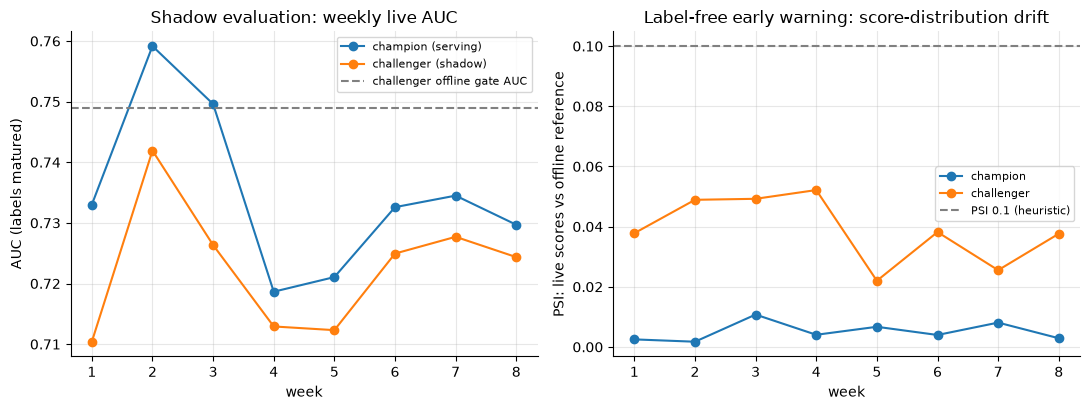

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(shadow.index, shadow["champion AUC"], marker="o", label="champion (serving)")
ax.plot(shadow.index, shadow["challenger AUC (shadow)"], marker="o",
        label="challenger (shadow)")
ax.axhline(auc_chal_g, ls="--", color="gray", label="challenger offline gate AUC")
ax.set_xlabel("week")
ax.set_ylabel("AUC (labels matured)")
ax.set_title("Shadow evaluation: weekly live AUC")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(shadow.index, shadow["champion score PSI"], marker="o", label="champion")
ax.plot(shadow.index, shadow["challenger score PSI"], marker="o", label="challenger")
ax.axhline(0.1, ls="--", color="gray", label="PSI 0.1 (heuristic)")
ax.set_xlabel("week")
ax.set_ylabel("PSI: live scores vs offline reference")
ax.set_title("Label-free early warning: score-distribution drift")
ax.legend(fontsize=8)
plt.show()

Two detection layers fired, on two different clocks:

- **Week 1, no labels needed:** the challenger's live score distribution diverged from
  its own offline reference (elevated PSI) while the champion's stayed near zero. A
  model whose serving scores don't look like its validation scores has a broken path —
  you know this *immediately*. (This is the score-monitoring layer from
  [./01_drift_monitoring.ipynb](./01_drift_monitoring.ipynb), pointed at a launch.)
- **As labels matured:** the challenger's live AUC ran consistently *below* the champion
  it was supposed to beat, and far below its offline gate number. The ~15% of customers
  who never log in — the riskiest segment — arrive with `last_login_days = 0`, which the
  model reads as "logged in today": their risk is massively understated.

Verdict: **do not promote**. Zero customers were exposed. Root-cause, fix the feature
service, re-shadow (same eight weeks of logged traffic — another payoff of shadow logs):

In [22]:
fixed_log = []
for w, batch in enumerate(batches, start=1):
    s_champ = champion.predict_proba(batch[CHAMP_FEATURES])[:, 1]
    s_fixed = challenger.predict_proba(batch[FEATURES])[:, 1]   # nulls preserved
    yb = batch["churned"].to_numpy()
    fixed_log.append({"week": w, "champion AUC": roc_auc_score(yb, s_champ),
                      "challenger AUC (fixed path)": roc_auc_score(yb, s_fixed)})
fixed = pd.DataFrame(fixed_log).set_index("week")
print(fixed.round(4).to_string())
print(f"\n8-week mean: champion {fixed['champion AUC'].mean():.4f} vs "
      f"fixed challenger {fixed['challenger AUC (fixed path)'].mean():.4f} "
      f"-> promote to canary")

# Bonus: the schema validator from section 2 flags the 'Ultra' launch on live traffic —
# a heads-up that the golden set is going stale and the next retrain must include Ultra.
print("\nvalidator on live week-1 traffic:")
for issue in validate_serving_batch(batches[0][CHAMP_FEATURES], schema):
    print(f"   - {issue}")

      champion AUC  challenger AUC (fixed path)
week                                           
1           0.7330                       0.7379
2           0.7592                       0.7748
3           0.7496                       0.7440
4           0.7186                       0.7264
5           0.7211                       0.7344
6           0.7326                       0.7531
7           0.7345                       0.7566
8           0.7297                       0.7448

8-week mean: champion 0.7348 vs fixed challenger 0.7465 -> promote to canary

validator on live week-1 traffic:
   - monthly_spend: 0.9% of values outside training range [11.98, 166.26]
   - plan: 5.1% unknown levels, e.g. ['Ultra']


### 5.2 Canary sizing: why canaries catch disasters, not improvements

A canary sends a small slice (say 5%) of customers through the new model *with real
actions*, watching business guardrails. How long until a churn regression of a given
size is detectable? Straight power math (details in
[../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)):

In [23]:
power = NormalIndPower()
base = 0.20
weekly_canary = 1_500          # 5% of ~30k scored customers per week
for delta in [0.05, 0.02, 0.005]:
    es = proportion_effectsize(base + delta, base)
    n = power.solve_power(effect_size=es, alpha=0.05, power=0.8, alternative="larger")
    print(f"detect +{delta:.1%} churn regression: n≈{n:,.0f} per arm "
          f"≈ {n / weekly_canary:.1f} weeks of 5% canary")

detect +5.0% churn regression: n≈860 per arm ≈ 0.6 weeks of 5% canary
detect +2.0% churn regression: n≈5,126 per arm ≈ 3.4 weeks of 5% canary
detect +0.5% churn regression: n≈79,873 per arm ≈ 53.2 weeks of 5% canary


A catastrophic regression pops within days; a subtle one would take a year of canary.
That's the division of labor: **canary = circuit breaker for disasters; A/B test =
measurement instrument for improvements.** For the model A/B test itself: randomize by
customer, primary metric is the business outcome, guardrail metrics with pre-registered
stopping rules — the full playbook is in
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb),
and it applies to models exactly as to any product change.

## 6. The senior ML-system checklist

The mental model interviewers want: a **loop with owners and gates**, not a line from
notebook to endpoint.

| Stage | Key questions | Concrete artifacts / tests | Typical owner |
|---|---|---|---|
| **Data** | Where does training data come from? Point-in-time correct? PII handled? | versioned snapshots + content hashes; freshness SLAs; schema contracts with producers | data eng |
| **Features** | One definition for train & serve? Staleness bounds? Leakage-safe? | shared feature pipeline / feature store; input schema validator at the serving boundary (§2) | ML eng + data eng |
| **Training** | Reproducible? Honest evaluation? | single `Pipeline` artifact (§1); pinned env + seeds + data hash (§3); leakage-safe CV | DS / applied scientist |
| **Validation** | Would I bet the product on this artifact? | golden-set eval, paired challenger-vs-champion CI, behavioral tests, prediction-diff regression tests (§3–4) — all in CI | DS owns tests; ML eng owns CI |
| **Deployment** | Can I ship gradually and roll back in minutes? | metadata sidecar + load-time smoke test (§1); shadow -> canary -> A/B ladder (§5); previous champion kept warm | ML eng / platform |
| **Monitoring** | Will I know before customers do? | input schema alerts, score PSI, sliced metrics, delayed-label AUC ([./01_drift_monitoring.ipynb](./01_drift_monitoring.ipynb)) | ML eng + DS on-call |
| **Retraining loop** | Scheduled or triggered? Same gates as humans? | retrain pipeline that must pass §4 gates automatically; auto-promotion criteria; rollback runbook | shared; runbook names a human |

One sentence to say out loud in an interview: *"Every stage has an owner, an artifact,
and a gate — and the retrained model goes through exactly the same gates as a hand-built
one."*

## 7. Pitfalls recap — plus one more that bites everyone

Demonstrated above, in code:

1. **Preprocess-then-split leaks** (§1): full-data target encoding inflated "test" AUC
   massively; production paid the difference — and got a worse model on top.
2. **Loose preprocessing artifacts drift** (§1–2): medians, category maps, and dummy
   layouts kept "in sync" by hope. One pipeline object, or eventually skew.
3. **`handle_unknown="ignore"` is a silencer** (§2): it keeps serving alive through
   benign novelty *and* swallows a lowercased-category catastrophe without a single log
   line. Pair it with an unknown-rate alert, never use it bare.
4. **Disappearing missingness is a red flag** (§2): upstream `fillna(0)` looks like
   cleaner data and is actually a units-level corruption.
5. **CSV is not a snapshot format** (§3): `"NA"` region became missing, floats drifted;
   parquet plus content hashes — and even then, normalize `None` vs `NaN` on load.
6. **Stochastic training components hide behavior changes** (§3): one `early_stopping`
   flag creates seed-to-seed prediction churn big enough to mask a real code change.
   Pin or remove randomness; measure the noise floor for what remains.
7. **Offline gates can't see the serving path** (§5): the challenger passed everything
   and was still broken in shadow. Gate the path, not just the pickle.

And one more classic, demonstrated below: **assuming `predict_proba[:, 1]` is the
positive class**. Column order follows `model.classes_` — the *sorted* labels. With
`0/1` targets that happens to work, so the habit forms; then someone switches to string
labels in a refactor and the assumption silently inverts every score.

In [24]:
y_str = pd.Series(np.where(y_train == 1, "churned", "retained"), index=y_train.index)
clf_str = Pipeline([
    ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM_COLS)])),
    ("clf", LogisticRegression(max_iter=2000, random_state=42)),
]).fit(X_train, y_str)

print(f"classes_: {clf_str.named_steps['clf'].classes_}")
naive = clf_str.predict_proba(X_valid)[:, 1]        # engineer assumes col 1 = positive
correct_col = list(clf_str.named_steps["clf"].classes_).index("churned")
correct = clf_str.predict_proba(X_valid)[:, correct_col]
print(f"AUC assuming column 1 is the positive class: {roc_auc_score(y_valid, naive):.4f}")
print(f"AUC indexing via classes_:                   {roc_auc_score(y_valid, correct):.4f}")

classes_: ['churned' 'retained']
AUC assuming column 1 is the positive class: 0.2664
AUC indexing via classes_:                   0.7336


`"churned" < "retained"` alphabetically, so column 1 is `P(retained)` — the "positive"
column landed at index 0 and every score inverted, with no error anywhere. An AUC of
0.26 at least *looks* broken; at 0.48 you might ship it. The defense is one line —
`col = list(model.classes_).index(positive_label)` — plus the behavioral gates from §4,
which catch the inversion structurally (every monotonicity check flips).

## 8. Interview corner

**Q1. "Walk me through shipping a churn model from notebook to production."**
Strong answer structure (artifacts, gates, rollout, loop): (1) refactor to a single
fitted pipeline — preprocessing and model in one object, one input contract; (2) pin
environment and seeds, snapshot + hash the training data, log training metrics in a
metadata sidecar with the artifact; (3) CI gates: golden-set eval vs current champion
with a paired CI, behavioral tests (monotonicity/invariance/sanity), prediction-diff vs
the reference; (4) rollout ladder: shadow (tests the serving path), canary on guardrails
(circuit breaker), then a customer-randomized A/B on the business metric; (5) monitoring
+ retraining loop where auto-retrains pass the same gates, with a named owner and a
rollback runbook. Seniority = mentioning ownership and rollback unprompted.

**Q2. "What is training–serving skew? Causes and defenses?"**
Definition: features computed differently at serve time than at training time — the
model is fine, its inputs lie. Causes: duplicated preprocessing across codebases, NA
semantics (`NaN` -> `0`/`""`), category normalization changes, dtype coercion at JSON
boundaries, unit changes, feature staleness. Defenses in layers: one serialized pipeline
(kills duplication); schema validation at the serving boundary (dtypes, ranges,
missing-rates, unknown-category rates — rate-based); log serving features and replay
them through the training path, diffing the result; score-distribution monitoring (skew
shows up as score drift within hours, no labels needed); shadow mode before exposure.

**Q3. "Offline AUC is up 2 points. Do you ship it?"**
Not yet. Is the 2 points real (paired CI on the delta, not two marginal CIs; golden set
fresh enough)? Does it survive behavioral gates and slices? Then shadow — offline eval
can't see the serving path. Then canary for guardrails. Then, because offline AUC is a
proxy, an A/B test on the business metric decides promotion; plenty of AUC-positive
models are business-neutral because the extra ranking power lands where decisions don't
change (same intervene/don't-intervene call either side of the threshold).

**Q4. "How would you A/B test a new model safely?"**
Randomize by customer (request-level randomization gives one customer inconsistent
treatment and pollutes the outcome); primary metric = business outcome (retention/
revenue), not AUC; guardrails (complaints, latency, intervention volume) with
pre-registered stopping rules; power the test for the expected effect size — and if the
MDE math says months, say so and negotiate scope (see
[../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)).
Ramp: shadow -> 5% canary -> 50/50. Keep the champion warm for instant rollback.

**Q5. "A scheduled retrain just changed 30% of predictions. Bug or expected?"**
First, establish the noise floor: if the pipeline is deterministic, *any* diff demands
explanation; if it has stochastic components, retrain the old code/data with different
seeds to measure baseline churn and judge against it. Second, slice the diffs and check
provenance — the data-snapshot hash and schema-validator logs reveal upstream changes,
a config diff reveals code changes. Third, regardless of the explanation, the retrain
must still pass golden-set and behavioral gates before promotion, and downstream
thresholds must be retuned if the score distribution moved.

**Q6. "Shadow vs canary vs A/B — when do you use which?"**
Shadow: zero-risk, tests the serving path and score distributions, gives live accuracy
once labels mature — but says nothing about the impact of *acting* on scores. Canary:
small bounded risk, catches disasters fast, hopelessly underpowered for small effects.
A/B: the only one that measures causal business impact; needs the most traffic and
time. They compose in that order; skipping shadow to save a week is how serving-path
bugs reach customers.

**Q7. "How do you roll back a bad model?"**
You can only roll back what you kept: versioned immutable artifacts with sidecars, the
previous champion still deployed (warm) behind a router flag, and backward-compatible
feature dependencies (don't delete a feature the old model needs the moment the new one
ships). Rollback is a config flip, minutes not days; the incident review then uses the
sidecar (data hash, env pins, metrics) to reproduce and diagnose offline.

## 9. Key takeaways

- Preprocessing fitted on the full dataset before splitting is leakage; target encoding
  is the worst offender. Split first; let `Pipeline` + cross-fitting handle the rest.
- Ship **one fitted object**, not a model plus a folklore of medians and mappings. The
  pipeline *is* the input contract.
- Serialize with a **metadata sidecar**: version, env pins, data hash, training metrics,
  smoke rows + expected scores. A model should prove its identity at load time.
- Training–serving skew fails **silently**: unknown categories encode to zeros, imputed
  defaults masquerade as data. Defend with rate-based schema validation at the boundary
  and score-distribution monitoring behind it.
- Reproducibility = deterministic training + pinned environment + hashed binary
  snapshots (parquet, not CSV). Retrain-and-diff is then a sharp regression test; where
  randomness remains, measure the noise floor before setting thresholds.
- Pre-deploy gates: frozen golden set, **paired** challenger-vs-champion CI, behavioral
  tests. Multiple independent gates, because each misses something.
- Shadow tests the **path**, canary is a **circuit breaker**, the A/B test is the
  **measurement instrument**. In that order, and auto-retrains climb the same ladder.
- Offline metric gains are proxies; promotion decisions belong to business metrics.

## 10. Exercises

**Exercise 1 — units bug vs the schema validator.** The billing team re-platforms and
`monthly_spend` starts arriving in *cents*. (a) Show whether `validate_serving_batch`
catches it. (b) A subtler variant: a 10% price rise shifts spend within the training
range — show the range check misses it, then extend the validator with a per-feature
PSI check against the training distribution that catches it.

**Exercise 2 — a canary decision rule.** Simulate a 6-week canary where the new model
genuinely worsens churn by 2.5pp (0.20 -> 0.225), with 1,500 canary and 10,000 control
customers per week. Implement a weekly cumulative one-sided two-proportion z-test and
report in which week the canary trips (z > 1.645). Note the peeking caveat and where the
rigorous fix lives.

**Exercise 3 — a stability behavioral gate.** Add a local-stability test: perturb all
numeric features by ±2% multiplicative noise and measure the 99th percentile score
change. Compare champion (linear) vs challenger (trees) and decide what threshold you
would gate on, knowing trees are step functions.

In [25]:
# --- Solution 1 ----------------------------------------------------------------
cents_batch = X_clean.assign(monthly_spend=X_clean["monthly_spend"] * 100)   # cents bug
subtle_batch = X_clean.assign(monthly_spend=X_clean["monthly_spend"] * 1.1)  # +10% shift

print("(a) cents bug vs the plain validator:")
for issue in validate_serving_batch(cents_batch, schema):
    print(f"   - {issue}")

print("\n(b) +10% shift vs the plain validator:",
      validate_serving_batch(subtle_batch, schema) or "no violations — missed!")


def validate_with_psi(df, schema, train_df, psi_threshold=0.01, **kw):
    """Plain checks + a distribution check per numeric feature."""
    issues = validate_serving_batch(df, schema, **kw)
    for c, spec in schema.items():
        if spec["kind"] == "num" and c in df.columns and pd.api.types.is_numeric_dtype(df[c]):
            v = psi(train_df[c].dropna(), df[c].dropna())
            if v > psi_threshold:
                issues.append(f"{c}: distribution PSI {v:.3f} vs training "
                              f"(> {psi_threshold})")
    return issues


for name, batch in [("clean batch", X_clean), ("+10% spend batch", subtle_batch)]:
    issues = validate_with_psi(batch, schema, old_raw[CHAMP_FEATURES])
    print(f"\nPSI-extended validator, {name}:",
          "accepted" if not issues else "")
    for i in issues:
        print(f"   - {i}")

(a) cents bug vs the plain validator:
   - monthly_spend: 91.6% of values outside training range [11.98, 166.26]

(b) +10% shift vs the plain validator: no violations — missed!

PSI-extended validator, clean batch: accepted

PSI-extended validator, +10% spend batch: 
   - monthly_spend: distribution PSI 0.040 vs training (> 0.01)


Range checks catch category errors (wrong units); only distribution checks catch scale
shifts *within* the historical range. The 0.01 threshold isn't sacred — calibrate it on
clean batches exactly as done for PSI nulls in
[./01_drift_monitoring.ipynb](./01_drift_monitoring.ipynb).

In [26]:
# --- Solution 2 ----------------------------------------------------------------
p_ctrl_true, p_canary_true = 0.20, 0.225
n_canary_wk, n_ctrl_wk = 1_500, 10_000

canary_events = ctrl_events = canary_n = ctrl_n = 0
print("week | canary churn | control churn |    z  | decision")
for w in range(1, 7):
    canary_events += rng.binomial(n_canary_wk, p_canary_true)
    ctrl_events += rng.binomial(n_ctrl_wk, p_ctrl_true)
    canary_n += n_canary_wk
    ctrl_n += n_ctrl_wk
    p1, p0 = canary_events / canary_n, ctrl_events / ctrl_n
    p_pool = (canary_events + ctrl_events) / (canary_n + ctrl_n)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / canary_n + 1 / ctrl_n))
    z = (p1 - p0) / se
    decision = "ABORT — roll back" if z > 1.645 else "continue"
    print(f"  {w}  |    {p1:.4f}    |    {p0:.4f}     | {z:5.2f} | {decision}")
    if z > 1.645:
        break

print("\nCaveat: testing cumulatively every week at a fixed 1.645 inflates false-abort "
      "risk (peeking). For a guardrail whose failure mode is 'we rolled back a fine "
      "model', that trade is often acceptable; the rigorous fix is a sequential test — "
      "see ../02_ab_testing/04_peeking_sequential.ipynb.")

week | canary churn | control churn |    z  | decision
  1  |    0.2267    |    0.1979     |  2.59 | ABORT — roll back

Caveat: testing cumulatively every week at a fixed 1.645 inflates false-abort risk (peeking). For a guardrail whose failure mode is 'we rolled back a fine model', that trade is often acceptable; the rigorous fix is a sequential test — see ../02_ab_testing/04_peeking_sequential.ipynb.


In [27]:
# --- Solution 3 ----------------------------------------------------------------
def stability_p99(model, X, feat_cols, scale=0.02, rng=None):
    base = model.predict_proba(X)[:, 1]
    Xp = X.copy()
    for c in feat_cols:
        Xp[c] = Xp[c] * (1 + rng.uniform(-scale, scale, len(Xp)))  # NaNs stay NaN
    pert = model.predict_proba(Xp)[:, 1]
    return float(np.quantile(np.abs(pert - base), 0.99))


p99_champ = stability_p99(champion, golden[CHAMP_FEATURES], NUM_COLS, rng=rng)
p99_chal = stability_p99(challenger, golden[FEATURES], NUM_COLS, rng=rng)
print(f"p99 |Δscore| under ±2% input noise: champion {p99_champ:.4f} | "
      f"challenger {p99_chal:.4f}")

p99 |Δscore| under ±2% input noise: champion 0.0102 | challenger 0.0637


The linear champion barely moves; the tree-based challenger jumps wherever a perturbed
value crosses a split threshold — that is inherent to trees, not a bug. A sensible gate:
measure realistic input jitter (sensor noise, rounding) from production logs, require
p99 score change under that jitter to stay below the smallest score difference your
downstream decisions can act on (for example, the width of a decision band around the
intervention threshold). Gate thresholds derive from *decisions*, not aesthetics.